## Step 1: Import libraries and load the data

In [4]:
# Import the libraries needed for analysis and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load the cleaned dataset and read the Date column as dates
df = pd.read_csv("Cleaned_Dataset1.csv", parse_dates=["Date"])


## Step 2: Create a folder to save the charts

In [5]:
# Create a folder named "charts" to save all chart images 
os.makedirs("charts", exist_ok=True)

# Confirm the folder was created
print(os.path.exists("charts"))

True


## Step 3: Check the shape of the data 


In [6]:
# Check the shape of the data (rows, columns)
df.shape

(1200, 14)

## Step 4: Colors and chart style

In [7]:
# Define the color palette: one highlight color and one neutral color
BLUE = "#0A66C2"   # highlight color for key insights
GREY = "#B8BEC8"   # neutral color for context

# Set a clean chart style: white background, no top/right borders
plt.rcParams["font.size"] = 12
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"

## Step 5: Calculate Key Business Metrics

In [8]:
# Calculate the key business metrics 
total_revenue = df["TotalPrice"].sum()
total_orders = len(df)
avg_order_value = df["TotalPrice"].mean()

# Print the metrics
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Average Order Value:", round(avg_order_value, 2))
print("Period:", df["Date"].min().date(), "to", df["Date"].max().date())

Total Revenue: 1264761.96
Total Orders: 1200
Average Order Value: 1053.97
Period: 2023-01-01 to 2025-06-30


## Step 6: Revenue by Product

Chair and Printer lead revenue at about 196K each, while Phone trails at 152K.

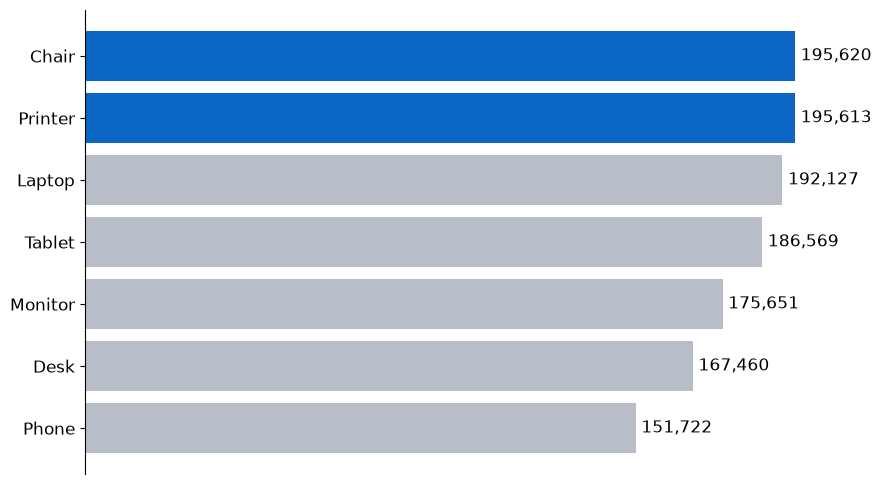

In [9]:
# Calculate total revenue for each product and sort from smallest to largest
product_revenue = df.groupby("Product")["TotalPrice"].sum().sort_values()

# Use grey for all bars, then highlight the top 2 products in blue
colors = [GREY] * len(product_revenue)
colors[-1] = BLUE
colors[-2] = BLUE

# Draw a horizontal bar chart
plt.figure(figsize=(9, 5))
bars = plt.barh(product_revenue.index, product_revenue.values, color=colors)

# Write the value directly on each bar 
plt.bar_label(bars, labels=[f"{v:,.0f}" for v in product_revenue.values], padding=4)

# Remove unnecessary chart elements (chartjunk)
plt.xticks([])
plt.gca().spines["bottom"].set_visible(False)

# Save the chart as an image and display it
plt.tight_layout()
plt.savefig("charts/01_revenue_by_product.png", dpi=300)
plt.show()

## Step 7: Revenue by Referral Source

Instagram is the top channel, generating approximately 275K in revenue.

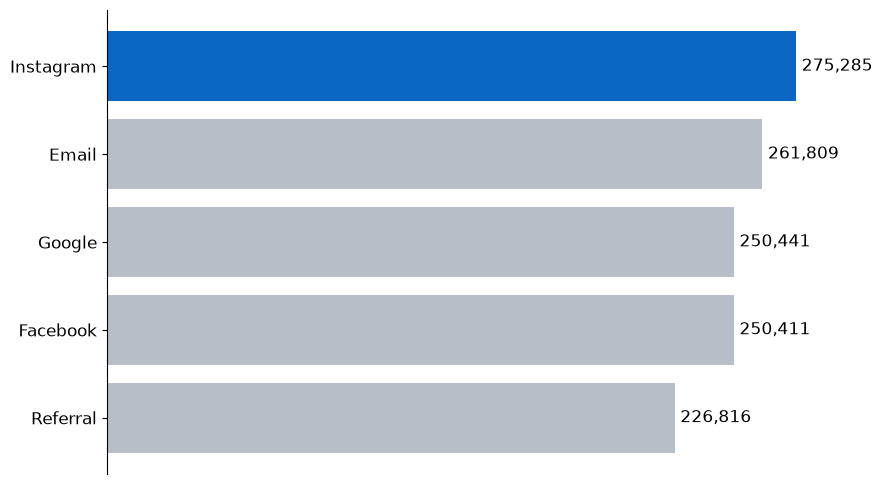

In [11]:
# Calculate total revenue for each referral source and sort ascending
referral_revenue = df.groupby("ReferralSource")["TotalPrice"].sum().sort_values()

# Highlight only the top channel in blue
colors = [GREY] * len(referral_revenue)
colors[-1] = BLUE

# Draw a horizontal bar chart with direct labels
plt.figure(figsize=(9, 5))
bars = plt.barh(referral_revenue.index, referral_revenue.values, color=colors)
plt.bar_label(bars, labels=[f"{v:,.0f}" for v in referral_revenue.values], padding=4)

# Remove unnecessary elements
plt.xticks([])
plt.gca().spines["bottom"].set_visible(False)

# Save and display
plt.tight_layout()
plt.savefig("charts/02_revenue_by_referral.png", dpi=300)
plt.show()

## Step 8:Monthly Revenue Trend
Monthly revenue is unstable, with a peak of 68K in June 2024

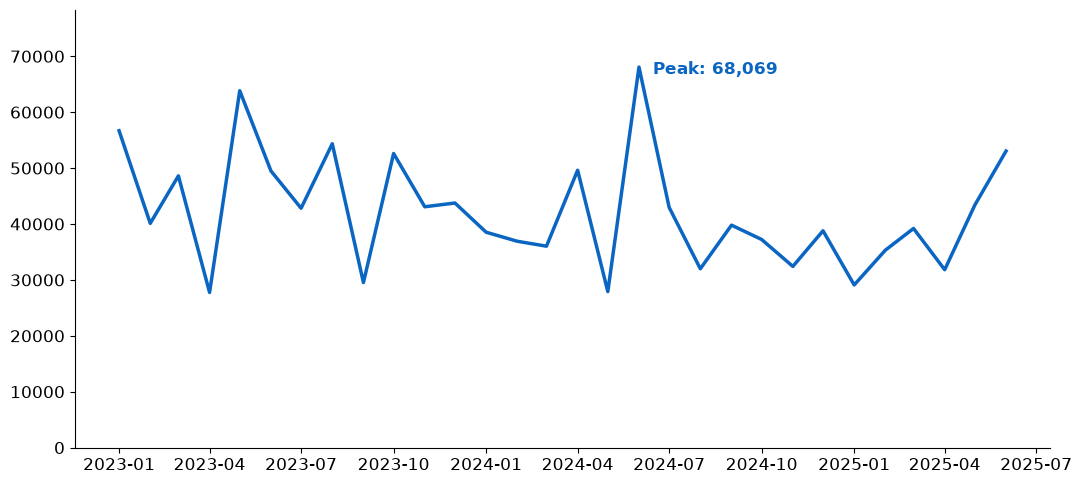

In [12]:
# Group revenue by month (MS = month start)
monthly_revenue = df.set_index("Date")["TotalPrice"].resample("MS").sum()

# Draw a line chart to show the trend over time
plt.figure(figsize=(11, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, color=BLUE, linewidth=2.5)

# Annotate only the peak month to draw attention to it
peak_month = monthly_revenue.idxmax()
plt.annotate(f"Peak: {monthly_revenue.max():,.0f}",
             (peak_month, monthly_revenue.max()),
             xytext=(10, -5), textcoords="offset points",
             color=BLUE, fontweight="bold")

# Start the Y-axis from zero for an honest view
plt.ylim(0, monthly_revenue.max() * 1.15)

# Save and display
plt.tight_layout()
plt.savefig("charts/03_monthly_trend.png", dpi=300)
plt.show()

## Step 9: Jan-Jun Comparison
Jan-Jun revenue fell about 19% from 2023 to 2025

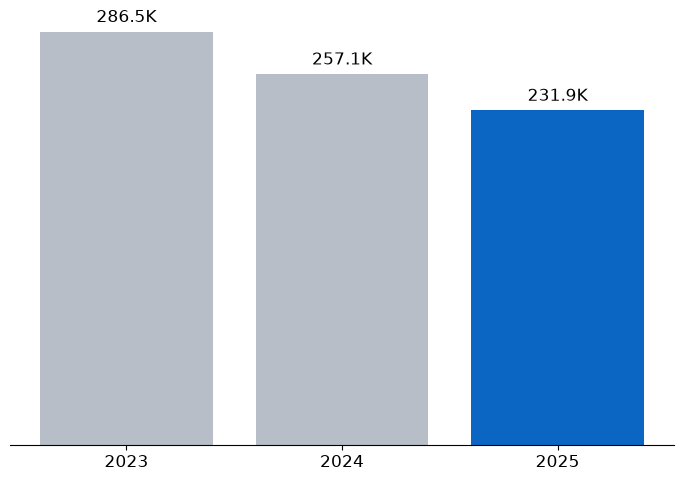

Change 2023 to 2025: -19.1 %


In [13]:
# Keep only January to June, because 2025 data ends in June (fair comparison)
h1_data = df[df["Date"].dt.month <= 6]

# Calculate total revenue for each year
h1_revenue = h1_data.groupby(h1_data["Date"].dt.year)["TotalPrice"].sum()

# Grey for 2023 and 2024, blue for 2025 (the key insight)
colors = [GREY, GREY, BLUE]

# Draw a column chart (Y-axis starts at zero by default)
plt.figure(figsize=(7, 5))
bars = plt.bar(h1_revenue.index.astype(str), h1_revenue.values, color=colors)
plt.bar_label(bars, labels=[f"{v/1000:.1f}K" for v in h1_revenue.values], padding=4)

# Remove unnecessary elements
plt.yticks([])
plt.gca().spines["left"].set_visible(False)

# Save and display
plt.tight_layout()
plt.savefig("charts/04_h1_comparison.png", dpi=300)
plt.show()

# Calculate the percentage change from 2023 to 2025
change = (h1_revenue.iloc[-1] / h1_revenue.iloc[0] - 1) * 100
print("Change 2023 to 2025:", round(change, 1), "%")


## Step 10: Order Status

Cancelled and Returned orders account for 41.4% of all orders, while only 19.2% are Delivered.

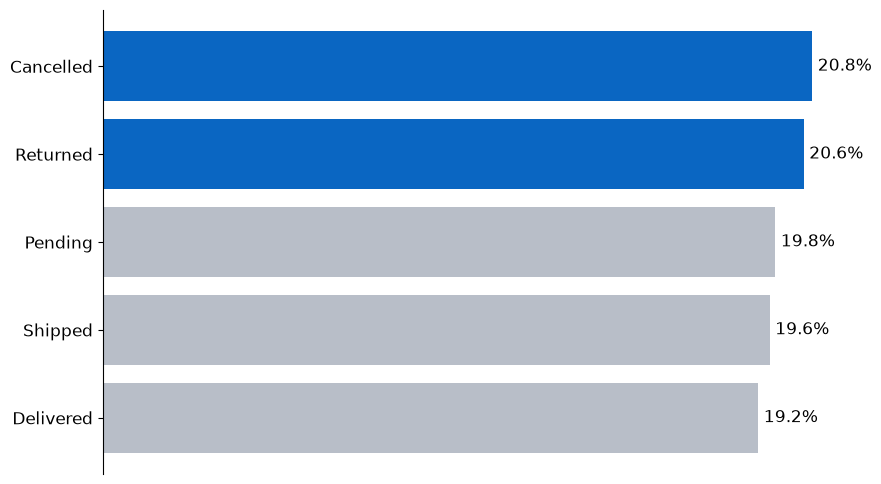

In [14]:
# Calculate the percentage share of each order status and sort ascending
status_share = (df["OrderStatus"].value_counts(normalize=True) * 100).sort_values()

# Highlight Cancelled and Returned (the top two) in blue
colors = [GREY] * len(status_share)
colors[-1] = BLUE
colors[-2] = BLUE

# Draw a horizontal bar chart with percentage labels
plt.figure(figsize=(9, 5))
bars = plt.barh(status_share.index, status_share.values, color=colors)
plt.bar_label(bars, labels=[f"{v:.1f}%" for v in status_share.values], padding=4)

# Remove unnecessary elements
plt.xticks([])
plt.gca().spines["bottom"].set_visible(False)

# Save and display
plt.tight_layout()
plt.savefig("charts/05_order_status.png", dpi=300)
plt.show()

## Step 11: Average Order Value by Payment Method
Credit Card orders have the highest average value (1,128)

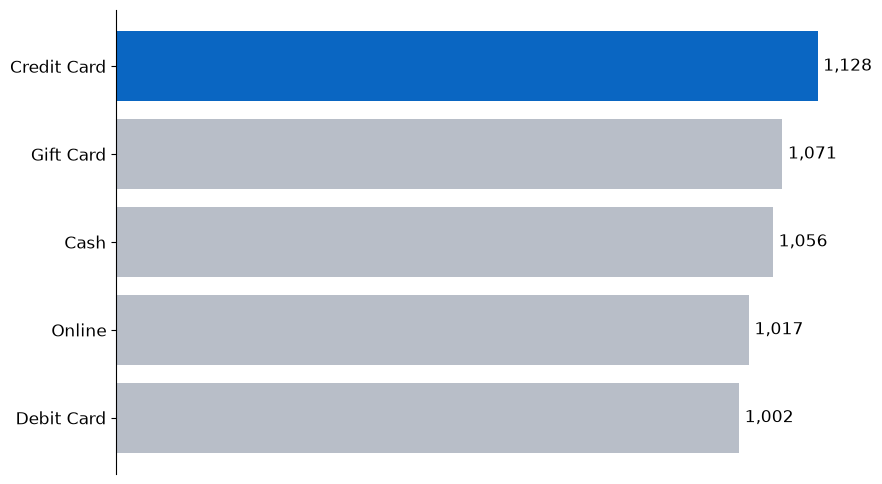

In [15]:
# Calculate the average order value for each payment method and sort ascending
payment_aov = df.groupby("PaymentMethod")["TotalPrice"].mean().sort_values()

# Highlight only the highest one in blue
colors = [GREY] * len(payment_aov)
colors[-1] = BLUE

# Draw a horizontal bar chart with direct labels
plt.figure(figsize=(9, 5))
bars = plt.barh(payment_aov.index, payment_aov.values, color=colors)
plt.bar_label(bars, labels=[f"{v:,.0f}" for v in payment_aov.values], padding=4)

# Remove unnecessary elements
plt.xticks([])
plt.gca().spines["bottom"].set_visible(False)

# Save and display
plt.tight_layout()
plt.savefig("charts/06_payment_aov.png", dpi=300)
plt.show()